# Question 4 — Predicting the Primary Purpose of Social Media Use

**Research question:** Can a user's primary purpose for using social media be predicted from their usage characteristics?

The target variable is `Purpose_Of_Use`, which contains four categories: `Entertainment`, `Education`, `Networking`, and `News`. Therefore, this is a **multiclass classification problem**.

Two feature sets will be compared:

| Feature set                   | Predictors                               |
| ----------------------------- | ---------------------------------------- |
| A — Usage behavior            | `Avg_Daily_Usage_Hours`, `Daily_Unlocks` |
| B — Usage behavior + platform | Previous features + `Most_Used_Platform` |

Four models will be evaluated:

* Logistic Regression
* Support Vector Machine
* Random Forest
* XGBoost

A `DummyClassifier` will be used as a baseline.

Because the target classes are imbalanced, the main evaluation metric will be **Macro F1**, alongside accuracy, confusion matrices, and cross-validation results.

A key question is whether the models learn meaningful behavioral patterns or mainly rely on `Most_Used_Platform`, which may act as a shortcut for predicting the target.


## 0. Setup & Data Loading

In [1]:
import os
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    LabelEncoder
)
from sklearn.impute import SimpleImputer

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.inspection import permutation_importance


# Reproducibility
RANDOM_STATE = 42

# Plotting style
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (9, 5)


# Cleaned dataset created by the first data-exploration notebook
DATA_PATH = "../dataset/student_social_media_cleaned.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"{DATA_PATH} was not found. "
        "Run data_exploration/01_data_overview_and_distributions.ipynb first."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (4998, 13)


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


## 1. Experimental Design

The data are split into 80% training and 20% testing sets using stratification to preserve the distribution of the four target classes.

Two feature sets are compared:

| Feature set | Predictors |
|---|---|
| A — Usage behavior | `Avg_Daily_Usage_Hours`, `Daily_Unlocks` |
| B — Behavior + Platform | Previous features + `Most_Used_Platform` |

Models are compared using five-fold stratified cross-validation on the training set.

The primary metric is **Macro F1**, supported by accuracy, balanced accuracy, and weighted F1. The test set remains untouched until the final model is selected.

In [2]:
# Target and feature sets
TARGET = "Purpose_Of_Use"
FEATURE_SETS = {
    "A - Usage behavior": ["Avg_Daily_Usage_Hours","Daily_Unlocks"],
    "B - Usage behavior + Platform": ["Avg_Daily_Usage_Hours","Daily_Unlocks","Most_Used_Platform"]
}
required_columns = [TARGET,"Avg_Daily_Usage_Hours","Daily_Unlocks","Most_Used_Platform"]
missing_columns = sorted(
    set(required_columns) - set(df.columns)
)
if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )
analysis_df = df[required_columns].copy()
assert analysis_df.isna().sum().sum() == 0, (
    "Missing values were found in the modeling variables."
)

# Encode the target for XGBoost
target_encoder = LabelEncoder()

analysis_df["Target_Encoded"] = target_encoder.fit_transform(
    analysis_df[TARGET]
)

CLASS_NAMES = list(target_encoder.classes_)

print("Target encoding:")
for class_id, class_name in enumerate(CLASS_NAMES):
    print(f"{class_id}: {class_name}")


# Stratified train-test split
train_df, test_df = train_test_split(analysis_df,test_size=0.20,
random_state=RANDOM_STATE,
    stratify=analysis_df["Target_Encoded"]
)

y_train = train_df["Target_Encoded"]
y_test = test_df["Target_Encoded"]
# Stratified cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)
SCORING = {
    "Accuracy": "accuracy",
    "Balanced Accuracy": "balanced_accuracy",
    "Macro F1": "f1_macro",
    "Weighted F1": "f1_weighted"
}
print(f"\nTraining rows: {len(train_df):,}")
print(f"Test rows: {len(test_df):,}")

print("\nTraining target distribution:")
print(
    train_df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .astype(str) + "%"
)

print("\nTest target distribution:")
print(
    test_df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .astype(str) + "%"
)

Target encoding:
0: Education
1: Entertainment
2: Networking
3: News

Training rows: 3,998
Test rows: 1,000

Training target distribution:
Purpose_Of_Use
Entertainment    51.05%
Education        21.86%
Networking       15.86%
News             11.23%
Name: proportion, dtype: str

Test target distribution:
Purpose_Of_Use
Entertainment    51.0%
Education        21.9%
Networking       15.9%
News             11.2%
Name: proportion, dtype: str


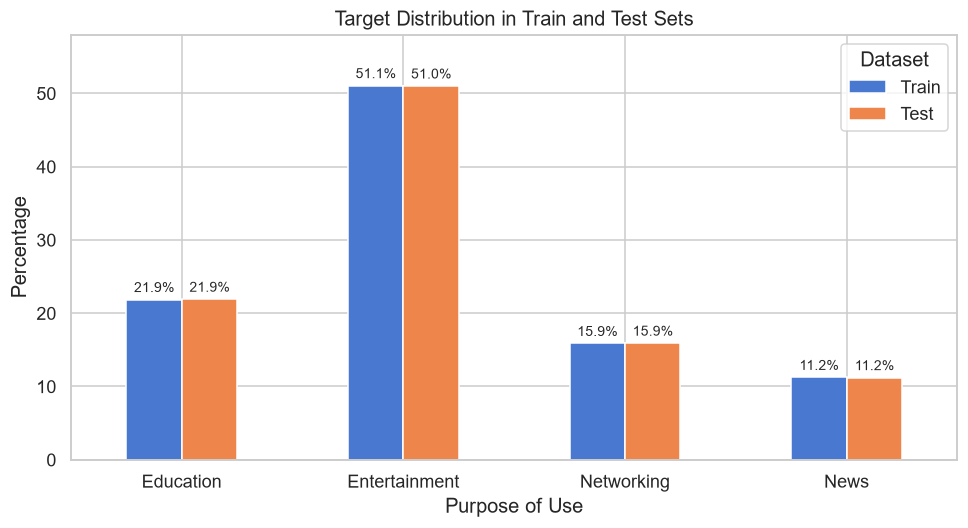

In [3]:
train_dist = (
    train_df[TARGET]
    .value_counts(normalize=True)
    .rename("Train")
)

test_dist = (
    test_df[TARGET]
    .value_counts(normalize=True)
    .rename("Test")
)

dist_df = pd.concat([train_dist, test_dist], axis=1).fillna(0)
dist_df = dist_df.loc[CLASS_NAMES] * 100

ax = dist_df.plot(kind="bar", figsize=(9, 5))

ax.set_title("Target Distribution in Train and Test Sets")
ax.set_xlabel("Purpose of Use")
ax.set_ylabel("Percentage")
ax.set_ylim(0, 58)
ax.legend(title="Dataset")
ax.tick_params(axis="x", rotation=0)

# Add percentages above the bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

The target distribution is clearly imbalanced: `Entertainment` represents approximately half of the observations, while `News` is the smallest class. The nearly identical train and test distributions confirm that stratified splitting preserved the original class proportions. Therefore, Macro F1 and balanced accuracy will be considered alongside standard accuracy.

## 2. Behavioral Patterns by Purpose of Use

Before training the models, we examine whether daily usage hours and daily unlocks differ across the four purpose-of-use categories.

Strong separation between the groups would suggest that behavioral characteristics contain predictive information. Substantial overlap would indicate that predicting the target from behavior alone may be difficult.

Avg_Daily_Usage_Hours              Daily_Unlocks              
                                mean median   std          mean median    std
Purpose_Of_Use                                                               
Education                       5.05    5.2  1.86        171.08  171.0  47.55
Entertainment                   5.10    5.1  1.59        171.80  171.0  41.33
Networking                      5.00    4.8  1.50        169.38  167.0  39.00
News                            5.19    5.3  1.66        174.70  177.0  43.22

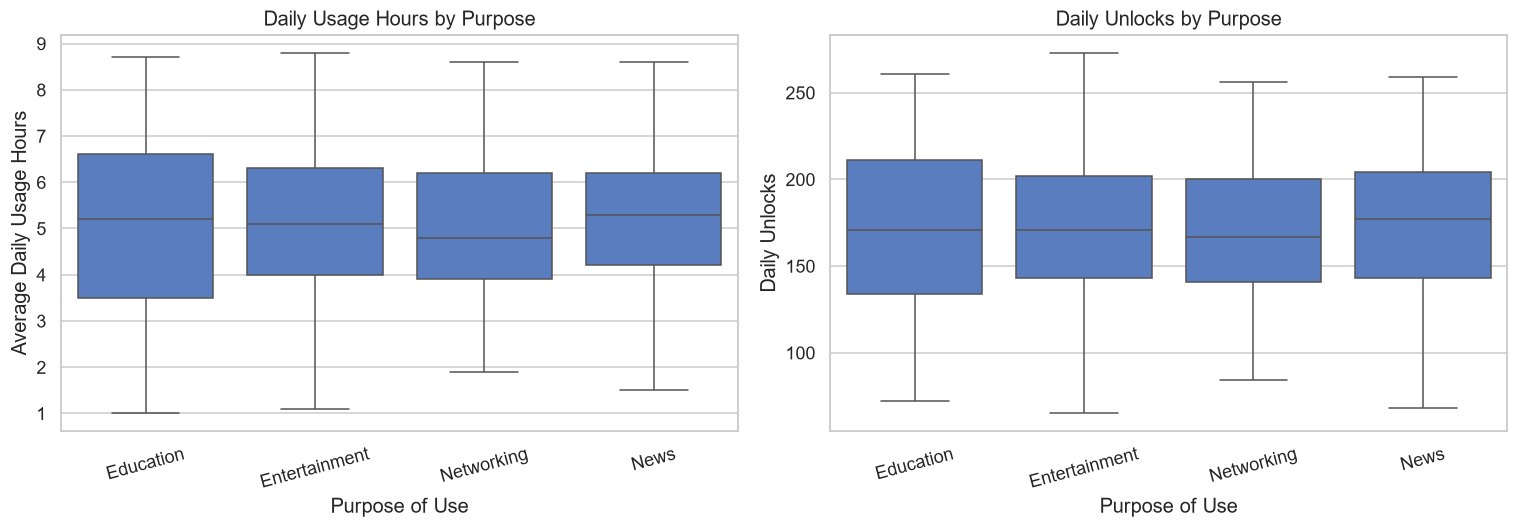

In [4]:
BEHAVIOR_FEATURES = [
    "Avg_Daily_Usage_Hours",
    "Daily_Unlocks"
]

behavior_summary = (
    train_df
    .groupby(TARGET, observed=True)[BEHAVIOR_FEATURES]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(behavior_summary)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=train_df,
    x=TARGET,
    y="Avg_Daily_Usage_Hours",
    order=CLASS_NAMES,
    showfliers=False,
    ax=axes[0]
)

axes[0].set_title("Daily Usage Hours by Purpose")
axes[0].set_xlabel("Purpose of Use")
axes[0].set_ylabel("Average Daily Usage Hours")


sns.boxplot(
    data=train_df,
    x=TARGET,
    y="Daily_Unlocks",
    order=CLASS_NAMES,
    showfliers=False,
    ax=axes[1]
)

axes[1].set_title("Daily Unlocks by Purpose")
axes[1].set_xlabel("Purpose of Use")
axes[1].set_ylabel("Daily Unlocks")

for ax in axes:
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

Mean daily usage ranges only from 5.00 to 5.19 hours, while the medians and interquartile ranges are also highly similar.

Daily unlock patterns show the same general behavior, with no category displaying clear separation. Therefore, these two variables may contain some weak predictive signal, but they are unlikely to distinguish the target classes reliably on their own.

## 2.1 Platform–Purpose Association

The behavioral features showed only weak visual separation. We now examine whether the user's most-used platform is more strongly associated with the target.

A very strong relationship may improve prediction substantially, but it may also indicate that the platform acts as a shortcut rather than representing a general behavioral pattern.

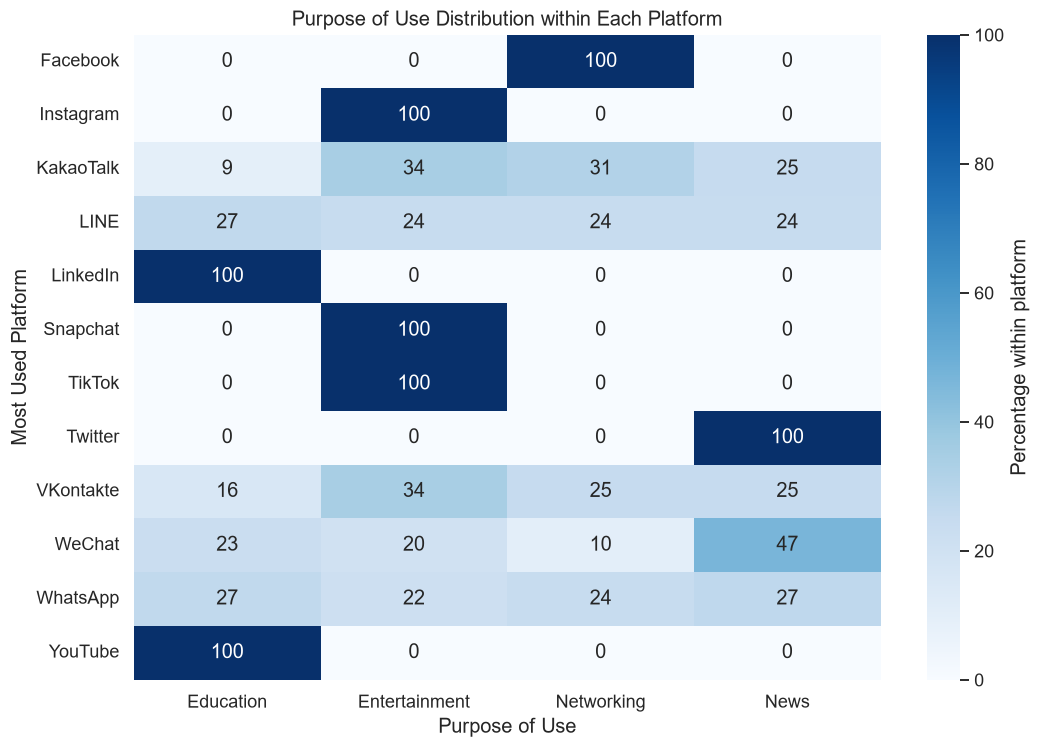

Chi-square statistic: 10,867.41
Degrees of freedom: 33
P-value: 0.000e+00
Cramér's V: 0.952


In [5]:
from scipy.stats import chi2_contingency

platform_purpose_counts = pd.crosstab(
    train_df["Most_Used_Platform"],
    train_df[TARGET]
)

platform_purpose_pct = pd.crosstab(
    train_df["Most_Used_Platform"],
    train_df[TARGET],
    normalize="index"
).mul(100)

# Preserve the target order
platform_purpose_counts = platform_purpose_counts[CLASS_NAMES]
platform_purpose_pct = platform_purpose_pct[CLASS_NAMES]
#display(platform_purpose_counts)
plt.figure(figsize=(10, 7))

sns.heatmap(
    platform_purpose_pct,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    cbar_kws={"label": "Percentage within platform"}
)

plt.title("Purpose of Use Distribution within Each Platform")
plt.xlabel("Purpose of Use")
plt.ylabel("Most Used Platform")
plt.tight_layout()
plt.show()


# Chi-square test and Cramér's V
chi2, p_value, dof, expected = chi2_contingency(
    platform_purpose_counts
)

n = platform_purpose_counts.to_numpy().sum()
rows, cols = platform_purpose_counts.shape

cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, cols - 1))
)

print(f"Chi-square statistic: {chi2:,.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.3e}")
print(f"Cramér's V: {cramers_v:.3f}")

The association between platform and purpose of use is extremely strong  
($\chi^2 = 10{,}867.41$, $p < 0.001$, Cramér's $V = 0.952$).

Several major platforms are associated exclusively with one purpose in the training data: Facebook with networking, Instagram, Snapchat and TikTok with entertainment, LinkedIn and YouTube with education, and Twitter with news.

In fact, assigning each platform its most common purpose would correctly describe approximately 95.2% of the training observations. Therefore, `Most_Used_Platform` is expected to provide a major predictive advantage. However, this result should be interpreted cautiously, since the models may learn a platform–purpose shortcut rather than general behavioral differences between users.

## 3. Preprocessing

All preprocessing steps are placed inside a pipeline to prevent information from the validation folds from leaking into model training.

Numerical features are standardized, while `Most_Used_Platform` is converted into binary indicators using one-hot encoding.

In [6]:
NUMERIC_FEATURES = [
    "Avg_Daily_Usage_Hours",
    "Daily_Unlocks"
]

CATEGORICAL_FEATURES = [
    "Most_Used_Platform"
]


numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)


def build_preprocessor(feature_names):
    """Create preprocessing according to the selected feature set."""

    numeric_columns = [
        feature for feature in feature_names
        if feature in NUMERIC_FEATURES
    ]

    categorical_columns = [
        feature for feature in feature_names
        if feature in CATEGORICAL_FEATURES
    ]

    transformers = []

    if numeric_columns:
        transformers.append(
            ("numeric", numeric_transformer, numeric_columns)
        )

    if categorical_columns:
        transformers.append(
            ("categorical", categorical_transformer, categorical_columns)
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )


for feature_set_name, feature_names in FEATURE_SETS.items():
    preprocessor = build_preprocessor(feature_names)

    transformed_train = preprocessor.fit_transform(
        train_df[feature_names]
    )

    print(
        f"{feature_set_name}: "
        f"{len(feature_names)} original features → "
        f"{transformed_train.shape[1]} transformed features"
    )

A - Usage behavior: 2 original features → 2 transformed features
B - Usage behavior + Platform: 3 original features → 14 transformed features


## 4. Baseline and Initial Model Comparison

The four classification models are evaluated under the same five-fold stratified cross-validation procedure.

A `DummyClassifier` is included as a baseline. This stage provides an initial, untuned comparison; hyperparameter tuning will be performed only for the strongest candidates.

The test set remains untouched during model comparison.

In [7]:
from sklearn.base import clone

MODELS = {
    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    "Support Vector Machine": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="multi:softprob",
        num_class=len(CLASS_NAMES),
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=1
    )
}


model_results = []

for feature_set_name, feature_names in FEATURE_SETS.items():

    X_train_current = train_df[feature_names]

    for model_name, model in MODELS.items():

        model_pipeline = Pipeline(
            steps=[
                (
                    "preprocessor",
                    build_preprocessor(feature_names)
                ),
                (
                    "model",
                    clone(model)
                )
            ]
        )

        cv_scores = cross_validate(
            estimator=model_pipeline,
            X=X_train_current,
            y=y_train,
            cv=cv_strategy,
            scoring=SCORING,
            return_train_score=True,
            n_jobs=-1,
            error_score="raise"
        )

        model_results.append({
            "Feature Set": feature_set_name,
            "Model": model_name,

            "CV Accuracy": cv_scores[
                "test_Accuracy"
            ].mean(),

            "CV Balanced Accuracy": cv_scores[
                "test_Balanced Accuracy"
            ].mean(),

            "CV Macro F1": cv_scores[
                "test_Macro F1"
            ].mean(),

            "Macro F1 SD": cv_scores[
                "test_Macro F1"
            ].std(),

            "Train Macro F1": cv_scores[
                "train_Macro F1"
            ].mean(),

            "Fit Time": cv_scores[
                "fit_time"
            ].mean()
        })


results_df = (
    pd.DataFrame(model_results)
    .sort_values(
        by=["Feature Set", "CV Macro F1"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(
    results_df.style
    .format({
        "CV Accuracy": "{:.3f}",
        "CV Balanced Accuracy": "{:.3f}",
        "CV Macro F1": "{:.3f}",
        "Macro F1 SD": "{:.3f}",
        "Train Macro F1": "{:.3f}",
        "Fit Time": "{:.2f}"
    })
    .background_gradient(
        subset=["CV Macro F1"],
        cmap="Blues"
    )
)

,Feature Set,Model,CV Accuracy,CV Balanced Accuracy,CV Macro F1,Macro F1 SD,Train Macro F1,Fit Time
0,A - Usage behavior,Random Forest,0.496,0.380,0.385,0.015,0.758,7.78
1,A - Usage behavior,XGBoost,0.522,0.300,0.277,0.015,0.344,3.14
2,A - Usage behavior,Dummy Baseline,0.511,0.250,0.169,0.000,0.169,0.11
3,A - Usage behavior,Logistic Regression,0.511,0.250,0.169,0.000,0.169,0.10
4,A - Usage behavior,Support Vector Machine,0.511,0.250,0.169,0.000,0.169,1.44
5,B - Usage behavior + Platform,Random Forest,0.974,0.967,0.967,0.008,0.998,5.18
6,B - Usage behavior + Platform,XGBoost,0.968,0.960,0.959,0.010,0.990,3.65
7,B - Usage behavior + Platform,Logistic Regression,0.946,0.926,0.925,0.011,0.938,0.12
8,B - Usage behavior + Platform,Support Vector Machine,0.945,0.925,0.923,0.012,0.938,0.51
9,B - Usage behavior + Platform,Dummy Baseline,0.511,0.250,0.169,0.000,0.169,0.07


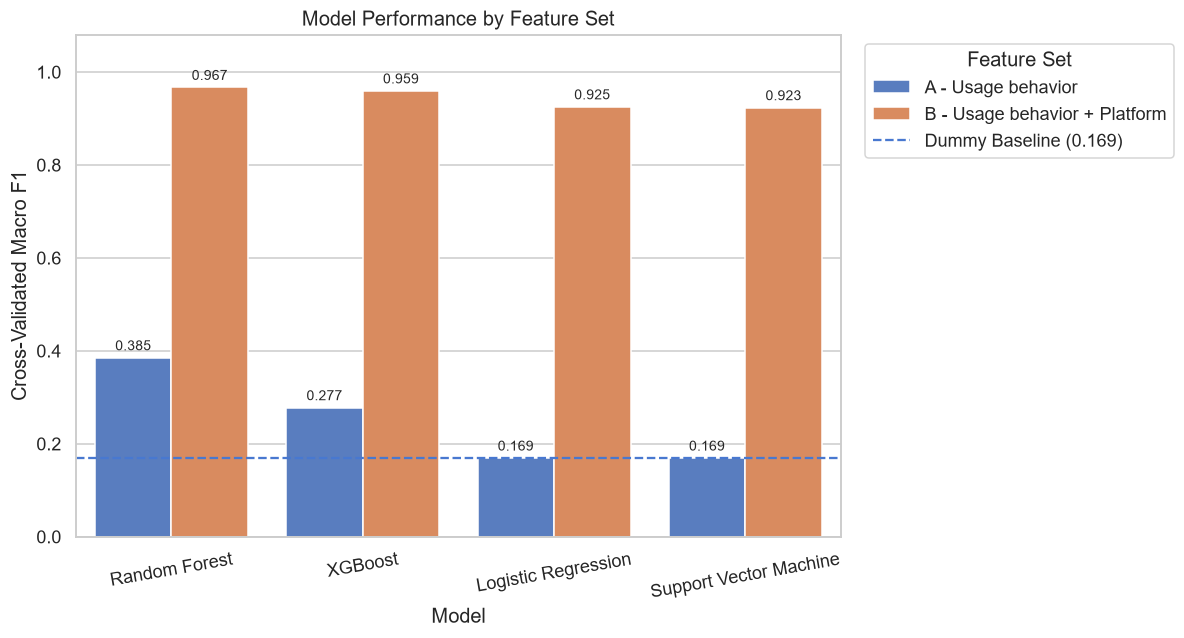

In [8]:
plot_df = results_df[
    results_df["Model"] != "Dummy Baseline"
].copy()

dummy_score = results_df.loc[
    results_df["Model"] == "Dummy Baseline",
    "CV Macro F1"
].iloc[0]

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=plot_df,
    x="Model",
    y="CV Macro F1",
    hue="Feature Set"
)

# Dummy baseline
ax.axhline(
    dummy_score,
    linestyle="--",
    linewidth=1.5,
    label=f"Dummy Baseline ({dummy_score:.3f})"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.set_title("Model Performance by Feature Set")
ax.set_xlabel("Model")
ax.set_ylabel("Cross-Validated Macro F1")
ax.set_ylim(0, 1.08)

plt.xticks(rotation=10)
plt.legend(
    title="Feature Set",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

Adding `Most_Used_Platform` produces a dramatic improvement across all models, while differences between the algorithms remain relatively small. This confirms that the platform variable is the main source of predictive power.

## 5. Hyperparameter Tuning

The two strongest tree-based models, Random Forest and XGBoost, are tuned using stratified cross-validation. Macro F1 is used as the optimization metric, while the test set remains untouched.

In [9]:
from sklearn.model_selection import RandomizedSearchCV

BEST_FEATURE_SET = FEATURE_SETS[
    "B - Usage behavior + Platform"
]

X_train_best = train_df[BEST_FEATURE_SET]

tuning_models = {
    "Random Forest": {
        "estimator": RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        "params": {
            "model__n_estimators": [200, 300, 500, 700],
            "model__max_depth": [None, 5, 10, 15, 20],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", "log2", None],
            "model__class_weight": [None, "balanced"]
        }
    },

    "XGBoost": {
        "estimator": XGBClassifier(
            objective="multi:softprob",
            num_class=len(CLASS_NAMES),
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        "params": {
            "model__n_estimators": [150, 250, 350, 500],
            "model__learning_rate": [0.02, 0.05, 0.1, 0.2],
            "model__max_depth": [2, 3, 4, 5, 6],
            "model__min_child_weight": [1, 3, 5],
            "model__subsample": [0.7, 0.85, 1.0],
            "model__colsample_bytree": [0.7, 0.85, 1.0],
            "model__reg_alpha": [0, 0.01, 0.1],
            "model__reg_lambda": [1, 2, 5]
        }
    }
}

tuned_models = {}
tuning_results = []

for model_name, config in tuning_models.items():

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                build_preprocessor(BEST_FEATURE_SET)
            ),
            (
                "model",
                config["estimator"]
            )
        ]
    )

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=config["params"],
        n_iter=25,
        scoring="f1_macro",
        cv=cv_strategy,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=0,
        return_train_score=True
    )

    search.fit(X_train_best, y_train)

    tuned_models[model_name] = search.best_estimator_

    best_index = search.best_index_

    tuning_results.append({
        "Model": model_name,
        "Best CV Macro F1": search.best_score_,
        "Train Macro F1": search.cv_results_[
            "mean_train_score"
        ][best_index],
        "CV Macro F1 SD": search.cv_results_[
            "std_test_score"
        ][best_index],
        "Best Parameters": search.best_params_
    })


initial_scores = (
    results_df[
        results_df["Feature Set"]
        == "B - Usage behavior + Platform"
    ]
    .set_index("Model")["CV Macro F1"]
)

tuning_summary = pd.DataFrame(tuning_results)

tuning_summary["Initial CV Macro F1"] = (
    tuning_summary["Model"].map(initial_scores)
)

tuning_summary["Improvement"] = (
    tuning_summary["Best CV Macro F1"]
    - tuning_summary["Initial CV Macro F1"]
)

tuning_summary = (
    tuning_summary[
        [
            "Model",
            "Initial CV Macro F1",
            "Best CV Macro F1",
            "Improvement",
            "Train Macro F1",
            "CV Macro F1 SD"
        ]
    ]
    .sort_values("Best CV Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(
    tuning_summary.style.format({
        "Initial CV Macro F1": "{:.3f}",
        "Best CV Macro F1": "{:.3f}",
        "Improvement": "{:+.3f}",
        "Train Macro F1": "{:.3f}",
        "CV Macro F1 SD": "{:.3f}"
    })
)

SELECTED_MODEL_NAME = "XGBoost"
final_model = tuned_models[SELECTED_MODEL_NAME]

,Model,Initial CV Macro F1,Best CV Macro F1,Improvement,Train Macro F1,CV Macro F1 SD
0,XGBoost,0.959,0.969,+0.010,0.998,0.008
1,Random Forest,0.967,0.964,-0.003,0.986,0.008


## 6. Final Evaluation on the Test Set

The tuned XGBoost model is now evaluated on the previously untouched test set. Performance is examined using overall metrics, class-specific results, and a normalized confusion matrix.

,Metric,Test Score
0,Accuracy,0.986
1,Balanced Accuracy,0.979
2,Macro F1,0.981
3,Weighted F1,0.986


,precision,recall,f1-score,support
Education,0.982,0.973,0.977,219
Entertainment,0.992,0.996,0.994,510
Networking,0.975,0.994,0.984,159
News,0.982,0.955,0.968,112


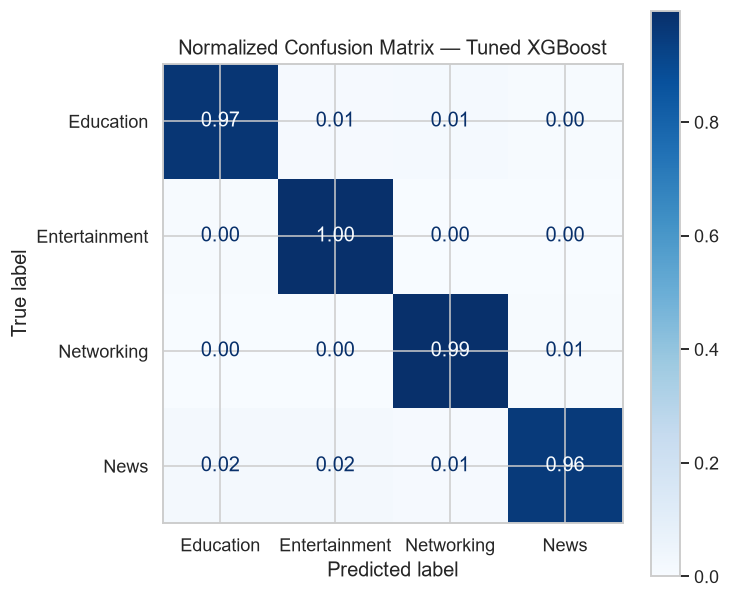

In [10]:
X_test_best = test_df[BEST_FEATURE_SET]

# The best estimator was already refitted on the full training set
y_test_pred = final_model.predict(X_test_best)


# Overall test metrics
test_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "Weighted F1"
    ],
    "Test Score": [
        accuracy_score(y_test, y_test_pred),
        balanced_accuracy_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred, average="macro"),
        f1_score(y_test, y_test_pred, average="weighted")
    ]
})

display(
    test_metrics.style.format({
        "Test Score": "{:.3f}"
    })
)


# Class-specific performance
report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_test_pred,
        labels=range(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )
).T

class_report = report_df.loc[
    CLASS_NAMES,
    ["precision", "recall", "f1-score", "support"]
]

display(
    class_report.style.format({
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1-score": "{:.3f}",
        "support": "{:.0f}"
    })
)


# Normalized confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=range(len(CLASS_NAMES)),
    display_labels=CLASS_NAMES,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=ax
)

ax.set_title("Normalized Confusion Matrix — Tuned XGBoost")
plt.tight_layout()
plt.show()

The tuned XGBoost model generalizes strongly to the unseen test set, achieving a Macro F1 of 0.981. Performance is high across all four classes, although `News` has the lowest recall at 0.955.However, these strong results should be interpreted in light of the dominant relationship between `Most_Used_Platform` and the target.

## 7. Feature Importance

Permutation importance measures how much model performance decreases when each feature is randomly shuffled. A larger decrease in Macro F1 indicates that the model relies more strongly on that feature.

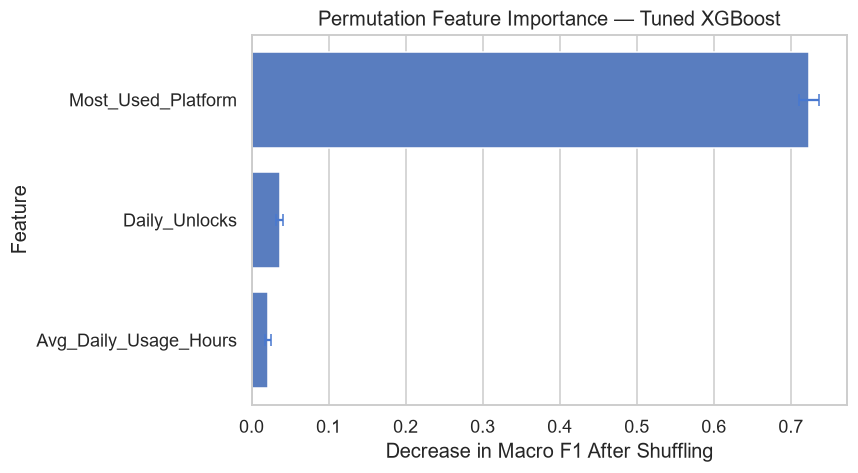

In [11]:
permutation_result = permutation_importance(
    final_model,
    X_test_best,
    y_test,
    scoring="f1_macro",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = (
    pd.DataFrame({
        "Feature": X_test_best.columns,
        "Importance": permutation_result.importances_mean,
        "Importance SD": permutation_result.importances_std
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)
plt.figure(figsize=(8, 4.5))

ax = sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

ax.errorbar(
    x=importance_df["Importance"],
    y=np.arange(len(importance_df)),
    xerr=importance_df["Importance SD"],
    fmt="none",
    capsize=4
)

ax.set_title("Permutation Feature Importance — Tuned XGBoost")
ax.set_xlabel("Decrease in Macro F1 After Shuffling")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

`Most_Used_Platform` dominates the model's predictions: shuffling it reduces Macro F1 by 0.724, compared with only minor decreases for the behavioral variables. This confirms that the model's strong performance is driven mainly by the platform–purpose relationship rather than by usage behavior alone.

## 8. Platform-Only Benchmark

To determine whether the machine-learning model adds value beyond the strong platform–purpose association, it is compared with a simple rule that assigns each platform its most common purpose in the training data.

In [12]:
# Learn the most common purpose for each platform from training data only
platform_to_purpose = (
    train_df
    .groupby("Most_Used_Platform")[TARGET]
    .agg(lambda values: values.mode().iloc[0])
)

fallback_class = train_df[TARGET].mode().iloc[0]

platform_rule_labels = (
    test_df["Most_Used_Platform"]
    .map(platform_to_purpose)
    .fillna(fallback_class)
)

platform_rule_pred = target_encoder.transform(
    platform_rule_labels
)

comparison_df = pd.DataFrame({
    "Approach": [
        "Platform-only rule",
        "Tuned XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, platform_rule_pred),
        accuracy_score(y_test, y_test_pred)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_test, platform_rule_pred),
        balanced_accuracy_score(y_test, y_test_pred)
    ],
    "Macro F1": [
        f1_score(y_test, platform_rule_pred, average="macro"),
        f1_score(y_test, y_test_pred, average="macro")
    ]
})

display(
    comparison_df.style.format({
        "Accuracy": "{:.3f}",
        "Balanced Accuracy": "{:.3f}",
        "Macro F1": "{:.3f}"
    })
)

,Approach,Accuracy,Balanced Accuracy,Macro F1
0,Platform-only rule,0.961,0.952,0.945
1,Tuned XGBoost,0.986,0.979,0.981


The platform-only rule already achieves a high Macro F1 of 0.945, confirming the strong relationship between platform and purpose of use. Tuned XGBoost improves the score to 0.981, showing that behavioral features provide a small but meaningful additional contribution.

## 9. Conclusions

The primary purpose of social media use can be predicted accurately when `Most_Used_Platform` is included. The tuned XGBoost model achieved a test Macro F1 of 0.981 and performed well across all four target classes.

However, usage behavior alone provided weak predictive power. A simple platform-only rule already achieved a Macro F1 of 0.945, showing that most of the prediction comes from the strong relationship between platform and purpose.

Therefore, the results suggest that the model mainly learns platform-specific patterns, while daily usage hours and unlock frequency provide only a small additional contribution. The findings should be interpreted cautiously, since these platform–purpose relationships may be specific to this dataset and may not generalize to other populations.
**Answer to the research question:** Yes, the primary purpose of social media use can be predicted with high accuracy, but mainly because the user's most-used platform strongly indicates the target category rather than because of general usage behavior.